In [1]:
import torch
import pandas as pd
import re
import os
import unicodedata
from unidecode import unidecode
from transformers import AutoTokenizer, AutoModelForTokenClassification

c:\Users\joaol\OneDrive\Desktop\MestradoBaseMédica\ProjetoDoutorado\envmestradobasemedica\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\joaol\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
import os
from dotenv import load_dotenv
from pathlib import Path

# Como o notebook está em 'corretor/src/3_avaliacao' e o .env em 'corretor',
# precisamos voltar duas pastas (../..) para achar o arquivo.
env_path = Path('../../.env')

# Carrega o arquivo explicitamente
load_dotenv(dotenv_path=env_path)

True

In [4]:
PATH_BASE_TESTES_FINAIS = os.getenv('PATH_BASE_TESTES_FINAIS')
PATH_GABARITO_CORRETOR = os.getenv('PATH_GABARITO_CORRETOR')
PATH_BASE_ENTROPIA_BERT = os.getenv('PATH_BASE_ENTROPIA_BERT')

In [5]:
df_texts = pd.read_csv(PATH_BASE_TESTES_FINAIS)

In [6]:
def preprocess(relato):
    def remove_stop_words(relato):
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        relato = re.sub(r'\@(\w*\d?)', " ", relato)
        relato = re.sub(r'([A-z1-9]*_+[A-z1-9]*)|(_+[A-z1-9]*)|([A-z1-9]*_+)', " ", relato)
        relato = re.sub(r"((?:HTTPS?|WWW)(?:\:\/\/?)?[*a-zA-Z0-9\.\/\?\:@\-_=#]+[\.][a-zA-Z]{2,6}[a-zA-Z0-9\.\&\/\?\:@\-_=#]*)", " ", relato)
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()
df_texts["relato_tratado"] = df_texts["relato"].apply(normalize_text).apply(preprocess)
df_texts

,n_bop,relato,nomes,relato_tratado
0,1,"SUBJETIVO NEFROLOGIA 220 A - ALICE MORAES , 37...","ALICE, MORAES, PAULO, SOUSA, MATOS",SUBJETIVO NEFROLOGIA ALICE MORAES ANOS PROFESS...
1,2,SUBJETIVO FISIOTERAPIA 402 A - RAFAELA MARTINS...,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",SUBJETIVO FISIOTERAPIA RAFAELA MARTINS ANOS DE...
2,3,SUBJETIVO CARDIOLOGIA 205 A - RICARDO GONÇALVE...,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",SUBJETIVO CARDIOLOGIA RICARDO GONCALVES ANOS A...
3,4,SUBJETIVO GASTROENTEROLOGIA PACIENTE : PEDRO S...,"PEDRO, SANTOS, LUISA, FERNANDES",SUBJETIVO GASTROENTEROLOGIA PACIENTE PEDRO SAN...
4,5,"SUBJETIVO ORTOPEDIA 78 A - JOANA MARTINS , 52 ...","JOANA, MARTINS, RENATA, COSTA",SUBJETIVO ORTOPEDIA JOANA MARTINS ANOS PROFESS...
...,...,...,...,...
1881,1882,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA SOAR...,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",SUBJETIVO UER SALA LARANJA CLAUDIA SOARES ALME...
1882,1883,SUBJETIVO UER - SALA AMARELA ID : RENATO AUGUS...,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",SUBJETIVO UER SALA AMARELA RENATO AUGUSTO MORE...
1883,1884,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",SUBJETIVO UER SALA AMARELA GERTRUDES SILVA CAR...
1884,1885,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : E...,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",SUBJETIVO CENTRO SAUDE CONSULTORIO ELIANA COST...


In [7]:
df_texts["relato_tratado"] = df_texts["relato"].apply(normalize_text).apply(preprocess)
df_texts

,n_bop,relato,nomes,relato_tratado
0,1,"SUBJETIVO NEFROLOGIA 220 A - ALICE MORAES , 37...","ALICE, MORAES, PAULO, SOUSA, MATOS",SUBJETIVO NEFROLOGIA ALICE MORAES ANOS PROFESS...
1,2,SUBJETIVO FISIOTERAPIA 402 A - RAFAELA MARTINS...,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",SUBJETIVO FISIOTERAPIA RAFAELA MARTINS ANOS DE...
2,3,SUBJETIVO CARDIOLOGIA 205 A - RICARDO GONÇALVE...,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",SUBJETIVO CARDIOLOGIA RICARDO GONCALVES ANOS A...
3,4,SUBJETIVO GASTROENTEROLOGIA PACIENTE : PEDRO S...,"PEDRO, SANTOS, LUISA, FERNANDES",SUBJETIVO GASTROENTEROLOGIA PACIENTE PEDRO SAN...
4,5,"SUBJETIVO ORTOPEDIA 78 A - JOANA MARTINS , 52 ...","JOANA, MARTINS, RENATA, COSTA",SUBJETIVO ORTOPEDIA JOANA MARTINS ANOS PROFESS...
...,...,...,...,...
1881,1882,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA SOAR...,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",SUBJETIVO UER SALA LARANJA CLAUDIA SOARES ALME...
1882,1883,SUBJETIVO UER - SALA AMARELA ID : RENATO AUGUS...,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",SUBJETIVO UER SALA AMARELA RENATO AUGUSTO MORE...
1883,1884,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",SUBJETIVO UER SALA AMARELA GERTRUDES SILVA CAR...
1884,1885,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : E...,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",SUBJETIVO CENTRO SAUDE CONSULTORIO ELIANA COST...


In [8]:
df_texts['relato_tratado'] = df_texts['relato_tratado'].str.lower()

In [9]:
df_texts

,n_bop,relato,nomes,relato_tratado
0,1,"SUBJETIVO NEFROLOGIA 220 A - ALICE MORAES , 37...","ALICE, MORAES, PAULO, SOUSA, MATOS",subjetivo nefrologia alice moraes anos profess...
1,2,SUBJETIVO FISIOTERAPIA 402 A - RAFAELA MARTINS...,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",subjetivo fisioterapia rafaela martins anos de...
2,3,SUBJETIVO CARDIOLOGIA 205 A - RICARDO GONÇALVE...,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",subjetivo cardiologia ricardo goncalves anos a...
3,4,SUBJETIVO GASTROENTEROLOGIA PACIENTE : PEDRO S...,"PEDRO, SANTOS, LUISA, FERNANDES",subjetivo gastroenterologia paciente pedro san...
4,5,"SUBJETIVO ORTOPEDIA 78 A - JOANA MARTINS , 52 ...","JOANA, MARTINS, RENATA, COSTA",subjetivo ortopedia joana martins anos profess...
...,...,...,...,...
1881,1882,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA SOAR...,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",subjetivo uer sala laranja claudia soares alme...
1882,1883,SUBJETIVO UER - SALA AMARELA ID : RENATO AUGUS...,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",subjetivo uer sala amarela renato augusto more...
1883,1884,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",subjetivo uer sala amarela gertrudes silva car...
1884,1885,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : E...,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",subjetivo centro saude consultorio eliana cost...


In [10]:
from transformers import AutoTokenizer, AutoModelForTokenClassification
import torch
import pandas as pd

In [11]:
model_name = "lfcc/bert-portuguese-ner"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForTokenClassification.from_pretrained(model_name)

In [12]:
def classify_tokens(text, max_words = 200):
    def split_text(text):
        words = text.split()
        chunks = [" ".join(words[i:i + max_words]) for i in range(0, len(words), max_words)]
        return chunks
        
    classified_tokens = []
    text_chunks = split_text(text)

    for chunk in text_chunks:
        inputs = tokenizer(chunk, return_tensors="pt", add_special_tokens=False)

        with torch.no_grad():
            outputs = model(**inputs)
            predictions = torch.argmax(outputs.logits, dim=2)

        label_list = model.config.id2label
        tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
        predictions = predictions[0].tolist()

        current_entity = []
        current_entity_type = None

        for token, prediction in zip(tokens, predictions):
            if token.startswith("##"):
                if current_entity:
                    current_entity.append(token[2:])
            else:
                if current_entity:
                    word = ''.join(current_entity)
                    label = 1 if "Pes" in current_entity_type else 0
                    classified_tokens.append({"palavras": word, "label": label})
                    current_entity = []

                current_entity = [token]
                current_entity_type = label_list[prediction]
                    
        if current_entity:
            token = ''.join(current_entity)
            label = 1 if "Pes" in current_entity_type else 0
            classified_tokens.append({"palavras": token, "label": label})
    return classified_tokens

In [13]:
classified_tokens = []
for idx, text in df_texts["relato_tratado"].items():
    classified_tokens.extend(classify_tokens(text))
classified_tokens_df = pd.DataFrame(classified_tokens)

In [14]:
classified_tokens_df_upper = classified_tokens_df.copy()

In [15]:
classified_tokens_df_upper['palavras'] = classified_tokens_df_upper['palavras'].str.upper()

In [16]:
gab = pd.read_csv(PATH_GABARITO_CORRETOR)

In [17]:
teste2 = classified_tokens_df_upper.merge(gab[['palavra', 'y']], left_on='palavras', right_on='palavra', how='left')

teste2['y'] = teste2['y'].fillna(0).astype(int)

teste2.value_counts(subset=['y'])

y
0    211932
1     19866
Name: count, dtype: int64

# Metricas


In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

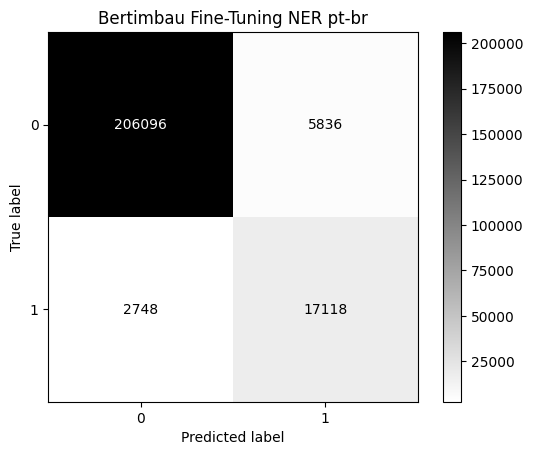

In [19]:
cm = confusion_matrix(teste2['y'], teste2['label'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title("Bertimbau Fine-Tuning NER pt-br")
plt.show()

In [20]:
accuracy = accuracy_score(teste2['y'], teste2['label'])
accuracy

0.9629677564085971

In [21]:
precision = precision_score(teste2['y'], teste2['label'])
precision

np.float64(0.7457523743138451)

In [22]:
recall = recall_score(teste2['y'], teste2['label'])
recall

np.float64(0.8616732105104198)

In [23]:
f1 = f1_score(teste2['y'], teste2['label'])
f1

np.float64(0.7995329285380663)

# Anonimização

In [24]:
def anon_tokens(text, text_orig):
    classified_tokens = classify_tokens(text)
    for token in classified_tokens:
        if token["label"] == 1:
            text_orig = text_orig.replace(token["palavras"].upper(), "***")
    return text_orig

In [25]:
anon_tokens(df_texts["relato_tratado"][0], df_texts["relato"][0])

'SUBJETIVO NEFROLOGIA 220 A - *** *** , 37 ***, PROFESSORA HORÁRIO : 08:10 RENAL : PACIENTE EM DIÁLISE PERITONEAL, SEM SINAIS DE PERITONITE. PERMEABILIDADE DE CATETER PRESERVADA. CRÉATININA ESTÁVEL 5,2 MG DL . HEMODINÂMICO : NORMOTENSO, SEM VARIAÇÕES SIGNIFICATIVAS DE PRESSÃO ARTERIAL PA 128 75 MMHG . FC EM RITMO REGULAR DE 82 BPM. RESPIRATÓRIO : SEM DISPNEIA OU OUTROS SINAIS DE SOBRECARGA HÍDRICA. AP : MURMÚRIOS VESICULARES PRESENTES E NORMAIS. ANEXOS : EDEMA 4 EM MEMBROS INFERIORES, PELE ÍNTEGRA E HIDRATADA, BOA COLORAÇÃO CUTÂNEA. CONDUTAS : MANTER DIÁLISE PERITONEAL CONFORME PRESCRIÇÃO. AJUSTE DE DIETA HIPO-SÓDICA. AVALIAÇÃO SEMANAL DE PARÂMETROS LABORATORIAIS E PESO SECO. ELABORADO E ASSINADO POR DR. *** *** *** , *** 122345 EM 20 07 2022 16:18. CONTACTAR *** ATRAVÉS DO TELEFONE 11 98765-4321 OU E-MAIL ***.***@ESCOLA.*** . *** EM JARDIM PAULISTA , SÃO *** . IDENTIFICADOR DO ATENDIMENTO 582734 .'

In [26]:
df_texts_anon = df_texts.copy()

In [27]:
for index, row in df_texts_anon.iterrows():
    df_texts_anon.at[index, "relato_anon"] = anon_tokens(row["relato_tratado"], row["relato"])

In [28]:
df_texts_anon

,n_bop,relato,nomes,relato_tratado,relato_anon
0,1,"SUBJETIVO NEFROLOGIA 220 A - ALICE MORAES , 37...","ALICE, MORAES, PAULO, SOUSA, MATOS",subjetivo nefrologia alice moraes anos profess...,"SUBJETIVO NEFROLOGIA 220 A - *** *** , 37 ***,..."
1,2,SUBJETIVO FISIOTERAPIA 402 A - RAFAELA MARTINS...,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",subjetivo fisioterapia rafaela martins anos de...,"SUBJETIVO FISIOTERAPIA 402 A - *** *** , 28 AN..."
2,3,SUBJETIVO CARDIOLOGIA 205 A - RICARDO GONÇALVE...,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",subjetivo cardiologia ricardo goncalves anos a...,"SUBJETIVO CARDIOLOGIA 205 A - *** GONÇALVES , ..."
3,4,SUBJETIVO GASTROENTEROLOGIA PACIENTE : PEDRO S...,"PEDRO, SANTOS, LUISA, FERNANDES",subjetivo gastroenterologia paciente pedro san...,SUBJETIVO GASTROENTEROLOGIA PACIENTE : *** ***...
4,5,"SUBJETIVO ORTOPEDIA 78 A - JOANA MARTINS , 52 ...","JOANA, MARTINS, RENATA, COSTA",subjetivo ortopedia joana martins anos profess...,"SUBJETIVO ORTOPEDIA 78 A - *** *** , 52 ***, P..."
...,...,...,...,...,...
1881,1882,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA SOAR...,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",subjetivo uer sala laranja claudia soares alme...,SUBJETIVO *** - *** *** ID : CLÁUDIA *** *** D...
1882,1883,SUBJETIVO UER - SALA AMARELA ID : RENATO AUGUS...,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",subjetivo uer sala amarela renato augusto more...,SUBJETIVO UER - SALA AMARELA ID : *** *** *** ...
1883,1884,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",subjetivo uer sala amarela gertrudes silva car...,SUBJETIVO *** - *** *** ID : *** *** *** DT **...
1884,1885,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : E...,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",subjetivo centro saude consultorio eliana cost...,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : *...


# entropy

In [29]:
import math
import numpy as np
import pandas as pd
from scipy.stats import entropy
from collections import Counter
import matplotlib.pyplot as plt
import scipy.stats as stats

É realizado o cálculo de entropia dos textos em claro e anonimizados, após isso realizada a comparação dos resultados obtidos.

- Foi criada uma tabela com o resultado da entropia de cada texto e realizada
- Realizado o cálculo da média de cada conjunto: Média dos resultados dos textos em claro e média dos resultados dos textos anonimizados. Assim podendo quantificar o impacto.
- Também foi realizado o cálculo do desvio padrão para mensurar diferença das entropias.

A entropia é calulada com base na probabilidade da ocorrência de cada caracter no texto. O resultado obtido da probabilidade de cada caracter é inserido para calculo da entropia utilizando a biblioteca entropy do scipy.stats que calcula a entropia com base na formula da entropia de shannon ( entropia da informação ).


In [30]:
def calculate_text_entropy(text, base=None):
    char_counts = Counter(text)
    total_chars = sum(char_counts.values())
    probabilities = np.array([count / total_chars for count in char_counts.values()])

    return entropy(probabilities, base=base)

resultado texto unicos

In [31]:
text = df_texts_anon['relato'].iloc[0]
text_anon = df_texts_anon['relato_anon'].iloc[0]

entropia do texto original

In [32]:
entropia = calculate_text_entropy(text, base=2)
entropia

np.float64(4.476727539660079)

entropia do texto anonimizado

In [33]:
entropia = calculate_text_entropy(text_anon, base=2)
entropia

np.float64(4.551119951132507)

resultado sobre toda a base de BOs

In [34]:
df_texts_anon['entrpy_result_orig'] = df_texts_anon['relato'].apply(lambda x: calculate_text_entropy(x, base=2))

In [35]:
df_texts_anon['entrpy_result_anon'] = df_texts_anon['relato_anon'].apply(lambda x: calculate_text_entropy(x, base=2))

In [36]:
save_df = df_texts_anon[["n_bop", "relato", "relato_anon", "entrpy_result_orig", "entrpy_result_anon"]]

In [37]:
save_df = save_df.rename(columns={"entrpy_result_orig":"bertimbau_text_orig", "entrpy_result_anon":"Entropy Bertimbau"})

In [38]:
save_df.to_csv(PATH_BASE_ENTROPIA_BERT, index=False)

### Verificando se há outliers

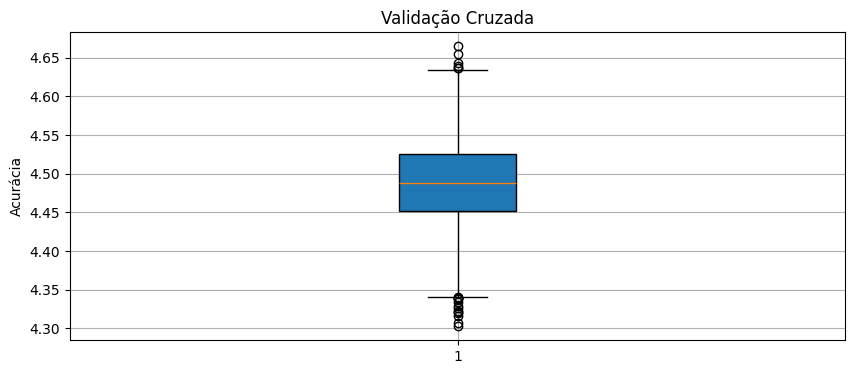

In [39]:
plt.figure(figsize=(10, 4))
plt.boxplot(df_texts_anon['entrpy_result_orig'], patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
plt.show()


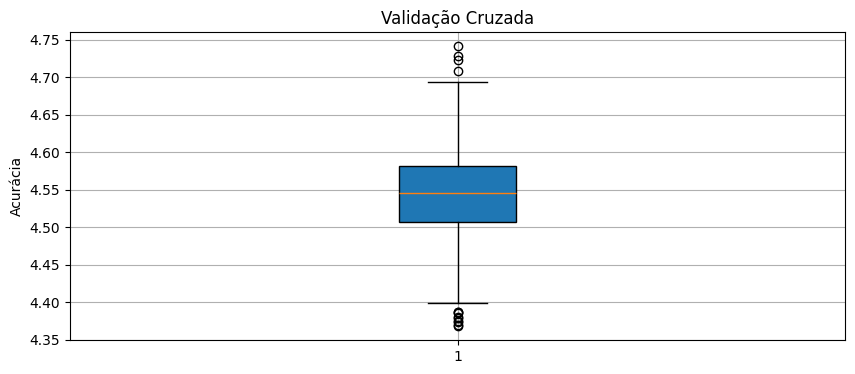

In [40]:
plt.figure(figsize=(10, 4))
plt.boxplot(df_texts_anon['entrpy_result_anon'], patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
plt.show()


#### Teste Shapiro para verificação da distribuição

In [41]:
shapiro_orig = stats.shapiro(df_texts_anon["entrpy_result_orig"])
shapiro_anon = stats.shapiro(df_texts_anon["entrpy_result_anon"])
print(f"Teste de Shapiro-Wilk para entrpy_result_orig: p-valor={shapiro_orig.pvalue}")
print(f"Teste de Shapiro-Wilk para entrpy_result_anon: p-valor={shapiro_anon.pvalue}")

Teste de Shapiro-Wilk para entrpy_result_orig: p-valor=0.15647685388543003
Teste de Shapiro-Wilk para entrpy_result_anon: p-valor=0.18275597280138095


#### Teste de Wilcoxon - verificação da significancia

recomendação para utilização desse teste em casos que houvesse outliers - o que foi visto nas células acima

In [42]:
w_stat, p_value_w = stats.wilcoxon(df_texts_anon["entrpy_result_orig"], df_texts_anon["entrpy_result_anon"])

In [43]:
print(f"{w_stat} \n{p_value_w}")

585.0 
4.544200803194403e-309


#### Teste T - para calculo de significancia também

In [44]:
t_stat, p_value_t = stats.ttest_rel(df_texts_anon["entrpy_result_orig"], df_texts_anon["entrpy_result_anon"])

In [45]:
print(f"{w_stat} \n{p_value_w}")

585.0 
4.544200803194403e-309


In [46]:
alpha = 0.05
if p_value_t < alpha:
    print("A diferença entre as entropias é estatisticamente significativa (Teste t).")
else:
    print("A diferença entre as entropias NÃO é estatisticamente significativa (Teste t).")

if p_value_w < alpha:
    print("A diferença entre as entropias é estatisticamente significativa (Teste de Wilcoxon).")
else:
    print("A diferença entre as entropias NÃO é estatisticamente significativa (Teste de Wilcoxon).")

A diferença entre as entropias é estatisticamente significativa (Teste t).
A diferença entre as entropias é estatisticamente significativa (Teste de Wilcoxon).


Media dos valores

In [47]:
df_texts_anon['entrpy_result_orig'].values.mean()

np.float64(4.48811474865559)

In [48]:
df_texts_anon['entrpy_result_anon'].values.mean()

np.float64(4.544431861248302)

In [49]:
np.std(df_texts_anon['entrpy_result_orig'].values)

np.float64(0.05642447566767289)

In [50]:
np.std(df_texts_anon['entrpy_result_anon'].values)

np.float64(0.055504056511780524)